# Question 1.
We now examine the differences between LDA and QDA.

(a) If the Bayes decision boundary is linear, do we expect LDA or
QDA to perform better on the training set? On the test set?

(b) If the Bayes decision boundary is non-linear, do we expect LDA
or QDA to perform better on the training set? On the test set?

(c) In general, as the sample size n increases, do we expect the test
prediction accuracy of QDA relative to LDA to improve, decline,
or be unchanged? Why?

(d) True or False: Even if the Bayes decision boundary for a given
problem is linear, we will probably achieve a superior test error
rate using QDA rather than LDA because QDA is flexible
enough to model a linear decision boundary. Justify your answer

# Answers to Question 1
(a) If Bayes decicion is linear, we expect LDA to perfom a better training set. This is because LDA exstimates a fewer parameters than QDA

(b) If Bayes decision boundary is non linear, we expect QDA to perform better on training set. This is because QDA can model non linear boundaries by allowing different different covariances matrices for each class.

(c) As sample size increases, we expect prediction accuracy of QDA to improve. This is because QDA estimates more parameters, so this gives it a high variance, and as size grows, the covariance estimate becomes more accurate. 

(d) True, this is because if Bayes decision is liner LDA will have a lower test rate than QDA. LDA estimates fewer parameters to the fact that it assumes they share the same covariance hence the test rate error is likely to be lower. 


# Question 2.
Suppose that we take a data set, divide it into equally-sized training
and test sets, and then try out two different classification procedures.
First we use logistic regression and get an error rate of 20 % on the
training data and 30 % on the test data. Next we use 1-nearest neighbors
(i.e. K = 1) and get an average error rate (averaged over both
test and training data sets) of 18 %. Based on these results, which
method should we prefer to use for classification of new observations?
Why?

# Answer to question 2
Logistic regression error rate = 20% training, 30% testing

K-1 nearest neighbors error rate = 18% on both both

So the method I would prefer would be K-1 nearest neighbor. This is because it has a test rate error of 18% campared to logistic regression of 30%. Test rate error is the best indicator of how best the model will perform on the new observation 




# Question 3.
This question should be answered using the Weekly data set, which
is part of the ISLP package. This data is similar in nature to the
Smarket data from this chapter’s lab, except that it contains 1, 089
weekly returns for 21 years, from the beginning of 1990 to the end of
2010.

(a) Produce some numerical and graphical summaries of the Weekly
data. Do there appear to be any patterns?

(b) Use the full data set to perform a logistic regression with
Direction as the response and the five lag variables plus Volume
as predictors. Use the summary function to print the results. Do
any of the predictors appear to be statistically significant? If so,
which ones?

(c) Compute the confusion matrix and overall fraction of correct
predictions. Explain what the confusion matrix is telling you
about the types of mistakes made by logistic regression.

(d) Now fit the logistic regression model using a training data period
from 1990 to 2008, with Lag2 as the only predictor. Compute the
confusion matrix and the overall fraction of correct predictions
for the held out data (that is, the data from 2009 and 2010).

(e) Repeat (d) using LDA.

(f) Repeat (d) using QDA.

(g) Repeat (d) using KNN with K = 1.

(h) Repeat (d) using naive Bayes.

(i) Which of these methods appears to provide the best results on
this data?

All libraries imported successfully
              Year         Lag1         Lag2         Lag3         Lag4  \
count  1089.000000  1089.000000  1089.000000  1089.000000  1089.000000   
mean   2000.048669     0.150585     0.151079     0.147205     0.145818   
std       6.033182     2.357013     2.357254     2.360502     2.360279   
min    1990.000000   -18.195000   -18.195000   -18.195000   -18.195000   
25%    1995.000000    -1.154000    -1.154000    -1.158000    -1.158000   
50%    2000.000000     0.241000     0.241000     0.241000     0.238000   
75%    2005.000000     1.405000     1.409000     1.409000     1.409000   
max    2010.000000    12.026000    12.026000    12.026000    12.026000   

              Lag5       Volume        Today  
count  1089.000000  1089.000000  1089.000000  
mean      0.139893     1.574618     0.149899  
std       2.361285     1.686636     2.356927  
min     -18.195000     0.087465   -18.195000  
25%      -1.166000     0.332022    -1.154000  
50%       0.234

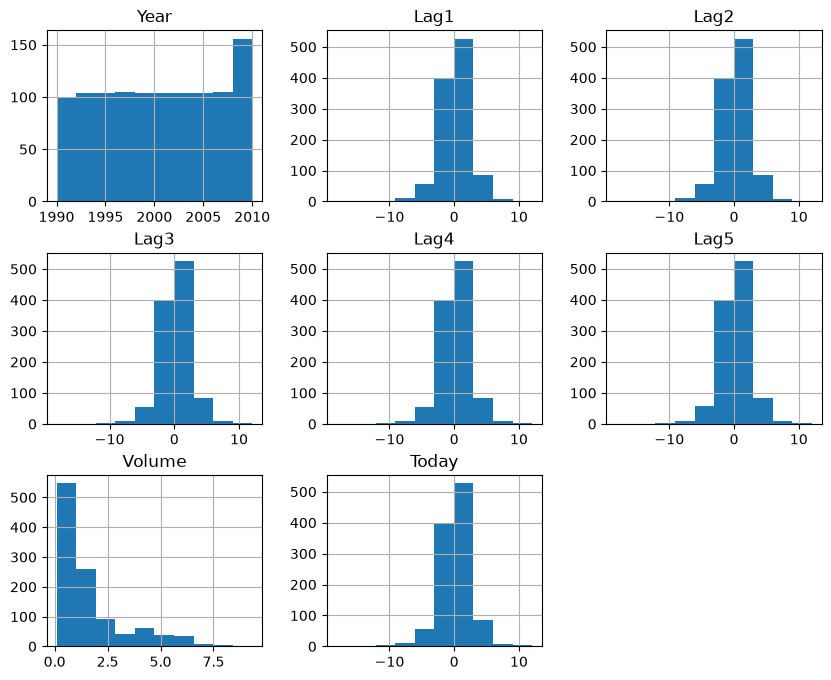

In [64]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from matplotlib.pyplot import subplots 
import statsmodels.api as sm 
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
summarize)
print("All libraries imported successfully") 
weekly = load_data("Weekly")
weekly 

#(a) Numerical and graphical summaries of the data
print(weekly.describe())


#Graphical summaries
weekly.hist(figsize=(10, 8))
plt.title("Histograms of Weekly Data")
plt.show()
 


In numerical and graphical summaries above, they are some similarities. The mean for lag1, lag2, lag3, lag3 and lag4 are around the same value which is 0.15. The same goes for the maximum values, standard deviation and minimun values 


In [65]:
#(b)Use the full data set to perform a logistic regression with
#Direction as the response and the five lag variables plus Volume
#as predictors. Use the summary function to print the results. Do
#any of the predictors appear to be statistically significant? If so,
#which ones? 
allvars = weekly.columns.drop(['Today', 'Direction', 'Year'])
design = MS(allvars)
X = design.fit_transform(weekly)
y = weekly.Direction 
y = weekly.Direction == 'Up'

glm = sm.GLM(
    y,
    X,
    family=sm.families.Binomial()
)
results = glm.fit()
summarize(results)


/home/codespace/.python/current/lib/python3.14/site-packages/sklearn/base.py:969: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  return self.fit(X, **fit_params).transform(X)


,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


From the logistic regression model fitted above, lag2 seems to be stastically significant because th ep value is less than 0.05

In [66]:
#(C)Compute the confusion matrix and overall fraction of correct
#predictions. Explain what the confusion matrix is telling you
#about the types of mistakes made by logistic regression.
confusion_matrix = pd.crosstab(y, results.predict() > 0.5, rownames=['Actual'], colnames=['Predicted'])
print("Confusion Matrix:")
print(confusion_matrix)
overall_accuracy = (54+557) / len(weekly)
print(f"Overall fraction of correct predictions: {overall_accuracy:.4f}")

Confusion Matrix:
Predicted  False  True 
Actual                 
False         54    430
True          48    557
Overall fraction of correct predictions: 0.5611


In [67]:
#(d)Now fit the logistic regression model using a training data period
#from 1990 to 2008, with Lag2 as the only predictor. Compute the
#confusion matrix and the overall fraction of correct predictions
#for the held out data (that is, the data from 2009 and 2010).
train = weekly[weekly.Year <= 2008]
test = weekly[(weekly.Year >= 2009) & (weekly.Year <= 2010)]

X_train = sm.add_constant(train[['Lag2']])
y_train = train.Direction == 'Up'
X_test = sm.add_constant(test[['Lag2']])

model = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Binomial()
)
results = model.fit()

predictions = results.predict(X_test) > 0.5
confusion_matrix = pd.crosstab(
    test.Direction == 'Up',
    predictions,
    rownames=['Actual'],
    colnames=['Predicted']
)
print(confusion_matrix)
print(f"Test accuracy: {(predictions == (test.Direction == 'Up')).mean():.4f}")

Predicted  False  True 
Actual                 
False          9     34
True           5     56
Test accuracy: 0.6250


In [68]:
#(e)Repeat this using LDA
from sklearn.discriminant_analysis import \
(LinearDiscriminantAnalysis as LDA ,
QuadraticDiscriminantAnalysis as QDA,) 
lda = LDA(store_covariance=True)
model = lda.fit(X_train, y_train)
predictions = model.predict(X_test)
confusion_matrix = pd.crosstab(
    test.Direction == 'Up',
    predictions,
    rownames=['Actual'],
    colnames=['Predicted']
)
print(confusion_matrix)
print(f"Test accuracy: {(predictions == (test.Direction == 'Up')).mean():.4f}") 




Predicted  False  True 
Actual                 
False          9     34
True           5     56
Test accuracy: 0.6250


In [69]:
#(f)Repeat this using QDA
from sklearn.naive_bayes import GaussianNB
qda = QDA(store_covariance=True)
model = qda.fit(X_train[['Lag2']], y_train)
predictions = model.predict(X_test[['Lag2']])
confusion_matrix = pd.crosstab(
    test.Direction == 'Up',
    predictions,
    rownames=['Actual'],
    colnames=['Predicted']
)
print(confusion_matrix)
print(f"Test accuracy: {(predictions == (test.Direction == 'Up')).mean():.4f}")

Predicted  True
Actual         
False        43
True         61
Test accuracy: 0.5865


In [70]:
#(g) Repeat (d) using KNN with K = 1.
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
model = knn.fit(X_train[['Lag2']], y_train)
predictions = model.predict(X_test[['Lag2']])
confusion_matrix = pd.crosstab(
    test.Direction == 'Up',
    predictions,
    rownames=['Actual'],
    colnames=['Predicted']
)
print(confusion_matrix)
print(f"Test accuracy: {(predictions == (test.Direction == 'Up')).mean():.4f}")


Predicted  False  True 
Actual                 
False         16     27
True          19     42
Test accuracy: 0.5577


In [71]:
#(h)Repeat (d) using naive Bayes.
NB = GaussianNB()
model = NB.fit(X_train[['Lag2']], y_train)
predictions = model.predict(X_test[['Lag2']])
confusion_matrix = pd.crosstab(
    test.Direction == 'Up',
    predictions,
    rownames=['Actual'],
    colnames=['Predicted']
)
print(confusion_matrix)
print(f"Test accuracy: {(predictions == (test.Direction == 'Up')).mean():.4f}")

Predicted  True
Actual         
False        43
True         61
Test accuracy: 0.5865


In [72]:
#(i)Which of these methods appears to provide the best results on this data?
print("Based on the test accuracy, LDA provides the best results on this data with an accuracy of 0.6250)")

Based on the test accuracy, LDA provides the best results on this data with an accuracy of 0.6250)


# Question 4. 
In this problem, you will develop a model to predict whether a given car gets high or low gas mileage based on the Auto data set.

(a) Create a binary variable, mpg01, that contains a 1 if mpg contains
a value above its median, and a 0 if mpg contains a value below
its median. You can compute the median using the median()
method of the data frame. Note you may find it helpful to add
a column mpg01 to the data frame by assignment. Assuming you
have stored the data frame as Auto, this can be done as follows:
Auto['mpg01'] = mpg01

(b) Explore the data graphically in order to investigate the association
between mpg01 and the other features. Which of the other
features seem most likely to be useful in predicting mpg01? Scatterplots
and boxplots may be useful tools to answer this question.
Describe your findings.

(c) Split the data into a training set and a test set.

(d) Perform LDA on the training data in order to predict mpg01
using the variables that seemed most associated with mpg01 in (b). What is the test set of the error obtained?

(e) Perform QDA on the training data in order to predict mpg01
using the variables that seemed most associated with mpg01 in
(b). What is the test error of the model obtained?

(f) Perform logistic regression on the training data in order to predict
mpg01 using the variables that seemed most associated with
mpg01 in (b). What is the test error of the model obtained?

(g) Perform naive Bayes on the training data in order to predict
mpg01 using the variables that seemed most associated with mpg01
in (b). What is the test error of the model obtained?

(h) Perform KNN on the training data, with several values of K, in
order to predict mpg01. Use only the variables that seemed most
associated with mpg01 in (b). What test errors do you obtain?
Which value of K seems to perform the best on this data set?


In [73]:
#(a)Create a binary variable, mpg01, that contains a 1 if mpg contains
#a value above its median, and a 0 if mpg contains a value below
#its median. You can compute the median using the median()
#method of the data frame. Note you may find it helpful to add
#a column mpg01 to the data frame by assignment. Assuming you
#have stored the data frame as Auto, this can be done as follows:
#Auto['mpg01'] = mpg01
Auto = load_data("Auto")
Auto
Auto['mpg01'] = (Auto['mpg'] > Auto['mpg'].median()).astype(int)
Auto

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,mpg01
name,,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1,0
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1,0
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1,0
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1,0
ford torino,17.0,8,302.0,140,3449,10.5,70,1,0
...,...,...,...,...,...,...,...,...,...
ford mustang gl,27.0,4,140.0,86,2790,15.6,82,1,1
vw pickup,44.0,4,97.0,52,2130,24.6,82,2,1
dodge rampage,32.0,4,135.0,84,2295,11.6,82,1,1


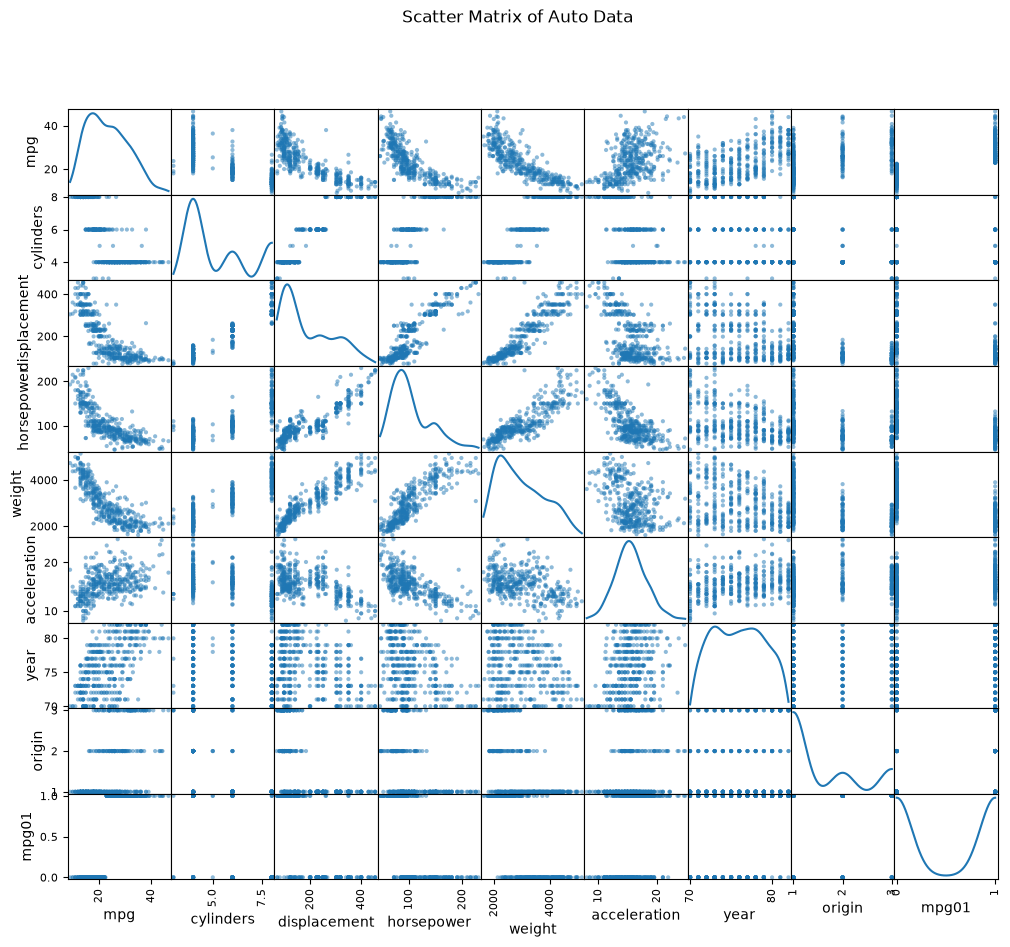

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,mpg01
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531,0.500000
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518,0.500639
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,0.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000,0.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,0.500000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000,1.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,1.000000


In [74]:
#(b)Explore the data graphically in order to investigate the association
#between mpg01 and the other features. Which of the other
#features seem most likely to be useful in predicting mpg01? Scatterplots
#and boxplots may be useful tools to answer this question.
#Describe your findings.
scatter_matrix = pd.plotting.scatter_matrix(Auto, figsize=(12, 10), diagonal='kde', alpha=0.5)
plt.suptitle("Scatter Matrix of Auto Data")
plt.show()
Auto.describe()


In [75]:
#(c)Split the data into a training set and a test set.
from sklearn.model_selection import train_test_split
X = Auto.drop('mpg01', axis=1)
y = Auto['mpg01']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
split_data = {
    'X_train': X_train,
    'X_test': X_test,
    'y_train': y_train,
    'y_test': y_test
}   
print(split_data)




{'X_train':                                    mpg  cylinders  displacement  horsepower  \
name                                                                          
triumph tr7 coupe                 35.0          4         122.0          88   
chevy s-10                        31.0          4         119.0          82   
vw pickup                         44.0          4          97.0          52   
datsun pl510                      27.0          4          97.0          88   
volvo 264gl                       17.0          6         163.0         125   
...                                ...        ...           ...         ...   
toyota corolla                    28.0          4          97.0          75   
amc concord                       19.4          6         232.0          90   
chevrolet chevelle concours (sw)  13.0          8         307.0         130   
chevrolet chevette                30.5          4          98.0          63   
chevrolet impala                  14.0  

In [79]:
#(d)Perform LDA on the training data in order to predict mpg01
#using the variables that seemed most associated with mpg01 in (b). What is the test set of the error obtained?
lda = LDA()
model = lda.fit(X_train[['displacement', 'weight', 'acceleration']], y_train)
y = Auto['mpg01']
model_predictions = model.predict(X_test[['displacement', 'weight', 'acceleration']])
confusion_matrix = pd.crosstab(y_test, model_predictions, rownames=['Actual'], colnames=['Predicted'])
print(confusion_matrix)
test_accuracy = (model_predictions == y_test).mean()
print(f"Test accuracy: {test_accuracy:.4f}")


Predicted   0   1
Actual           
0          57   8
1           1  52
Test accuracy: 0.9237


In [80]:
#(e)Perform QDA on the training data in order to predict mpg01
#using the variables that seemed most associated with mpg01 in
#(b). What is the test error of the model obtained?
qda = QDA()
model = qda.fit(X_train[['displacement', 'weight', 'acceleration']], y_train)
model_predictions = model.predict(X_test[['displacement', 'weight', 'acceleration']])
confusion_matrix = pd.crosstab(y_test, model_predictions, rownames=['Actual'], colnames=['Predicted'])
print(confusion_matrix)
test_error = 1 - (model_predictions == y_test).mean()
print(f"Test error: {test_error:.4f}")  



Predicted   0   1
Actual           
0          59   6
1           3  50
Test error: 0.0763


In [81]:
#(f)Perform logistic regression on the training data in order to predict
#mpg01 using the variables that seemed most associated with
#mpg01 in (b). What is the test error of the model obtained?
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()
model = log_reg.fit(X_train[['displacement', 'weight', 'acceleration']], y_train)
model_predictions = model.predict(X_test[['displacement', 'weight', 'acceleration']])
test_error = 1 - (model_predictions == y_test).mean()
print(f"Test error: {test_error:.4f}")  

Test error: 0.0847


In [82]:
#(g)Perform naive Bayes on the training data in order to predict
#mpg01 using the variables that seemed most associated with mpg01
#in (b). What is the test error of the model obtained?
NB = GaussianNB()
model = NB.fit(X_train[['displacement', 'weight', 'acceleration']], y_train)
model_predictions = model.predict(X_test[['displacement', 'weight', 'acceleration']])
confusion_matrix = pd.crosstab(y_test, model_predictions, rownames=['Actual'], colnames=['Predicted'])
print(confusion_matrix)
test_error = 1 - (model_predictions == y_test).mean()
print(f"Test error: {test_error:.4f}")

Predicted   0   1
Actual           
0          58   7
1           2  51
Test error: 0.0763


In [ ]:
#(h)Perform KNN on the training data, with several values of K, in
#order to predict mpg01. Use only the variables that seemed most
#associated with mpg01 in (b). What test errors do you obtain?
#Which value of K seems to perform the best on this data set?
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train[['displacement', 'weight', 'acceleration']], y_train)
knn_predictions = knn.predict(X_test[['displacement', 'weight', 'acceleration']])
test_error = 1 - (knn_predictions == y_test).mean()
print(f"Test error for K=1: {test_error:.4f}")

#for K=3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train[['displacement', 'weight', 'acceleration']], y_train)
knn_predictions = knn.predict(X_test[['displacement', 'weight', 'acceleration']])
test_error = 1 - (knn_predictions == y_test).mean()
print(f"Test error for K=3: {test_error:.4f}")

Test error for K=1: 0.1525
